# Sumativa 1 - Parte 3: Pruebas de hipótesis

**Dataset:** Framingham Heart Study (`data/framingham.csv`)
**Variable de interés:** `TenYearCHD` (1 = desarrolla enfermedad coronaria en 10 años, 0 = no)

Se contrastan dos hipótesis relacionadas con el riesgo de enfermedad coronaria:

1. Prueba 1: diferencia en la presión arterial sistólica media entre pacientes que desarrollan y no desarrollan enfermedad coronaria (prueba *t* de Welch para dos muestras).
2. Prueba 2: asociación entre el hábito de fumar y la enfermedad coronaria (prueba χ² de independencia).

Las variables utilizadas (`sysBP`, `currentSmoker`, `TenYearCHD`) no tienen valores faltantes, por lo que ambas pruebas usan las 4.240 observaciones del dataset original.

## 0. Configuración y carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

COLORES = {"principal": "#4C72B0", "riesgo": "#C44E52"}


def guardar_figura(nombre: str) -> None:
    """Ajusta el diseño, guarda la figura actual en la carpeta de figuras y la muestra."""
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()


df = pd.read_csv("../data/framingham.csv")
print(f"Observaciones: {df.shape[0]} | Variables: {df.shape[1]}")
df[["sysBP", "currentSmoker", "TenYearCHD"]].isna().sum()

Observaciones: 4240 | Variables: 16


sysBP            0
currentSmoker    0
TenYearCHD       0
dtype: int64

## 1. Nivel de significancia

Se usa α = 0,05, el valor habitual en investigación biomédica, que mantiene en 5 % la probabilidad de error tipo I (concluir que hay una diferencia o asociación cuando no la hay). Como la muestra es grande (n = 4.240), diferencias pequeñas pueden resultar significativas. Por eso, además del valor *p*, se reporta el tamaño del efecto para evaluar si la diferencia es relevante en la práctica.

In [2]:
ALPHA = 0.05


def decision(p_valor: float, alpha: float = ALPHA) -> str:
    """Devuelve la decisión sobre H0 comparando el valor p con el nivel de significancia."""
    return "se rechaza H0" if p_valor < alpha else "no se rechaza H0"


def d_cohen(x: pd.Series, y: pd.Series) -> float:
    """Tamaño del efecto d de Cohen para dos muestras, con desviación estándar combinada."""
    nx, ny = len(x), len(y)
    s_comb = np.sqrt(((nx - 1) * x.var() + (ny - 1) * y.var()) / (nx + ny - 2))
    return (x.mean() - y.mean()) / s_comb


def v_cramer(chi2: float, tabla: pd.DataFrame) -> float:
    """Tamaño del efecto V de Cramér para una tabla de contingencia."""
    n = tabla.values.sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

## 2. Prueba 1: presión sistólica y enfermedad coronaria

### 2.1 Hipótesis

Sea μ₁ la presión sistólica media de quienes desarrollan enfermedad coronaria y μ₀ la de quienes no la desarrollan:

- **H₀:** μ₁ = μ₀ (la presión sistólica media es igual en ambos grupos)
- **H₁:** μ₁ ≠ μ₀ (la presión sistólica media difiere entre grupos)

Se plantea una prueba bilateral, ya que no se asume a priori la dirección de la diferencia.

### 2.2 Descripción por grupo

In [3]:
chd = df.loc[df["TenYearCHD"] == 1, "sysBP"]
sano = df.loc[df["TenYearCHD"] == 0, "sysBP"]

resumen = df.groupby("TenYearCHD")["sysBP"].agg(
    n="count", media="mean", mediana="median", desv_est="std"
).round(2)
resumen.index = ["Sin CHD (0)", "Con CHD (1)"]
resumen

,n,media,mediana,desv_est
Sin CHD (0),3596,130.34,127.0,20.45
Con CHD (1),644,143.62,139.0,26.69


### 2.3 Verificación de supuestos

1. Independencia: se considera que cada fila pertenece a una persona distinta, de acuerdo con la descripción de la base. Esto no puede verificarse directamente porque no existe un identificador de participante.
2. Normalidad: se revisa con la prueba de D'Agostino-Pearson y gráficos Q-Q. Debido al tamaño de la muestra, también se observa la forma de las distribuciones y la presencia de valores extremos.
3. Homogeneidad de varianzas: se evalúa con la prueba de Levene centrada en la mediana.

In [4]:
for nombre, x in [("Sin CHD", sano), ("Con CHD", chd)]:
    k2, p = stats.normaltest(x)
    print(f"{nombre:8s} | D'Agostino K² = {k2:7.2f} | p = {p:.2e} | asimetría = {stats.skew(x):.2f}")

lev = stats.levene(chd, sano, center="median")
print(f"\nLevene: W = {lev.statistic:.2f} | p = {lev.pvalue:.2e}")

Sin CHD  | D'Agostino K² =  592.70 | p = 1.98e-129 | asimetría = 1.06
Con CHD  | D'Agostino K² =  108.94 | p = 2.21e-24 | asimetría = 1.00

Levene: W = 65.32 | p = 8.23e-16


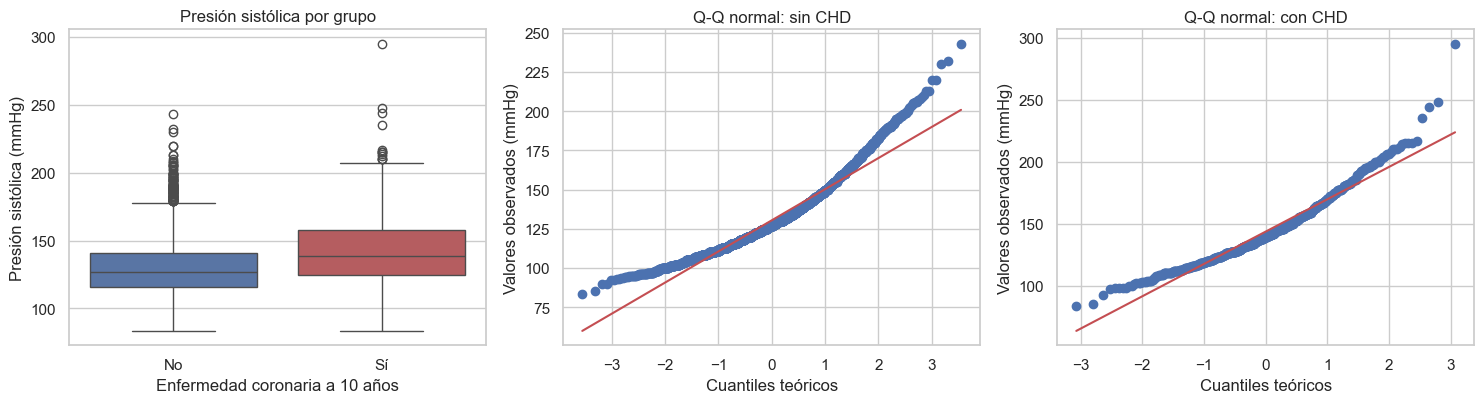

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
sns.boxplot(data=df, x="TenYearCHD", y="sysBP", hue="TenYearCHD", legend=False,
            ax=ax[0], palette=[COLORES["principal"], COLORES["riesgo"]])
ax[0].set_xticks([0, 1], ["No", "Sí"])
ax[0].set(xlabel="Enfermedad coronaria a 10 años", ylabel="Presión sistólica (mmHg)",
          title="Presión sistólica por grupo")
for a, (nombre, x) in zip(ax[1:], [("sin CHD", sano), ("con CHD", chd)]):
    stats.probplot(x, dist="norm", plot=a)
    a.set(title=f"Q-Q normal: {nombre}", xlabel="Cuantiles teóricos",
          ylabel="Valores observados (mmHg)")
guardar_figura("p3_fig1_sysbp_supuestos")

En ambos grupos se rechaza la normalidad (p < 0,001) y hay asimetría positiva, lo que también se ve en la curvatura de los gráficos Q-Q. La prueba de Levene rechaza la igualdad de varianzas: el grupo con CHD tiene mayor dispersión.

Decisión:
- La falta de normalidad no impide usar la prueba *t*: con n₀ = 3.596 y n₁ = 644, por el Teorema Central del Límite la media muestral tiene una distribución aproximadamente normal.
- Como las varianzas son distintas, se usa la prueba *t* de Welch, que no supone varianzas iguales.
- Como comprobación, se aplica también la prueba U de Mann-Whitney, que no requiere normalidad.

### 2.4 Ejecución de la prueba

In [6]:
t = stats.ttest_ind(chd, sano, equal_var=False)
ic = t.confidence_interval(confidence_level=1 - ALPHA)
dif = chd.mean() - sano.mean()
d = d_cohen(chd, sano)
mw = stats.mannwhitneyu(chd, sano, alternative="two-sided")

print(f"Diferencia de medias (CHD - sin CHD): {dif:.2f} mmHg")
print(f"IC 95% de la diferencia: [{ic.low:.2f}, {ic.high:.2f}] mmHg")
print(f"t de Welch = {t.statistic:.2f} | gl = {t.df:.1f} | p = {t.pvalue:.2e}")
print(f"d de Cohen = {d:.2f}")
print(f"Mann-Whitney U = {mw.statistic:.0f} | p = {mw.pvalue:.2e}")
print("Decisión:", decision(t.pvalue))

Diferencia de medias (CHD - sin CHD): 13.28 mmHg
IC 95% de la diferencia: [11.11, 15.45] mmHg
t de Welch = 12.01 | gl = 783.8 | p = 1.25e-30
d de Cohen = 0.62
Mann-Whitney U = 1519932 | p = 1.05e-36
Decisión: se rechaza H0


### 2.5 Interpretación

Como p < 0,05, se rechaza H₀. La presión sistólica media es distinta entre ambos grupos. Quienes desarrollan enfermedad coronaria tienen, en promedio, 13,3 mmHg más que quienes no la desarrollan (143,6 frente a 130,3 mmHg). El IC del 95 % para la diferencia va de 11,1 a 15,5 mmHg y no incluye cero.

La prueba U de Mann-Whitney también encuentra diferencias entre los grupos. Sin embargo, esta prueba compara los rangos de las distribuciones y no específicamente las medias, por lo que se utiliza como comprobación frente a la asimetría.

El tamaño del efecto es moderado (d de Cohen = 0,62). Para el proyecto, este resultado respalda la inclusión de la presión sistólica en los análisis posteriores. Aun así, la comparación es bivariada y no demuestra causalidad. Parte de la diferencia podría explicarse por la edad u otros factores.

## 3. Prueba 2: hábito de fumar y enfermedad coronaria

### 3.1 Hipótesis

- **H₀:** el hábito de fumar (`currentSmoker`) y el desarrollo de enfermedad coronaria (`TenYearCHD`) son independientes.
- **H₁:** existe asociación entre el hábito de fumar y el desarrollo de enfermedad coronaria.

Ambas variables son cualitativas nominales (binarias), por lo que se usa la prueba χ² de independencia sobre una tabla de contingencia 2×2.

### 3.2 Tabla de contingencia

In [7]:
tabla = pd.crosstab(df["currentSmoker"], df["TenYearCHD"])
tabla.index = ["No fumador", "Fumador"]
tabla.columns = ["Sin CHD", "Con CHD"]

tasas = pd.crosstab(df["currentSmoker"], df["TenYearCHD"], normalize="index")[1].mul(100).round(1)
tasas.index = tabla.index
display(tabla)
print("Tasa de CHD (%):")
print(tasas.to_string())

,Sin CHD,Con CHD
No fumador,1834,311
Fumador,1762,333


Tasa de CHD (%):
No fumador    14.5
Fumador       15.9


### 3.3 Verificación de supuestos

1. Independencia: se asume una observación por participante de acuerdo con la descripción del dataset; no existe un identificador que permita verificarlo directamente.
2. Frecuencias esperadas: todas las celdas deben tener una frecuencia esperada de al menos 5.

In [8]:
chi = stats.chi2_contingency(tabla, correction=True)
esperadas = pd.DataFrame(chi.expected_freq, index=tabla.index, columns=tabla.columns).round(1)
display(esperadas)
print("Frecuencia esperada mínima:", esperadas.values.min())

,Sin CHD,Con CHD
No fumador,1819.2,325.8
Fumador,1776.8,318.2


Frecuencia esperada mínima: 318.2


La frecuencia esperada mínima es 318,2, muy por sobre 5, así que el supuesto se cumple. Por ser una tabla 2×2 se aplica la corrección de continuidad de Yates.

### 3.4 Ejecución de la prueba

In [9]:
print(f"χ² = {chi.statistic:.3f} | gl = {chi.dof} | p = {chi.pvalue:.4f}")
print(f"V de Cramér = {v_cramer(chi.statistic, tabla):.3f}")
print("Decisión:", decision(chi.pvalue))

χ² = 1.497 | gl = 1 | p = 0.2211
V de Cramér = 0.019
Decisión: no se rechaza H0


### 3.5 Interpretación

Como p = 0,22 > 0,05, no se rechaza H₀: en la muestra completa no hay evidencia de asociación entre fumar y la enfermedad coronaria. La tasa de CHD es parecida en fumadores (15,9 %) y no fumadores (14,5 %), y la V de Cramér (0,019) es casi cero.

Esto no significa que fumar no tenga efecto. Una posible explicación es la edad como variable de confusión: en este dataset los fumadores son en promedio más jóvenes que los no fumadores (47,7 vs. 51,4 años), y la edad es uno de los principales factores de riesgo coronario. Para revisarlo, se comparan las tasas de CHD dentro de tramos de edad.

Edad media por hábito de fumar:
currentSmoker
No fumador    51.4
Fumador       47.7


,No fumador,Fumador
age,,
≤ 45,4.1,8.4
46-55,13.1,18.6
> 55,24.6,28.6


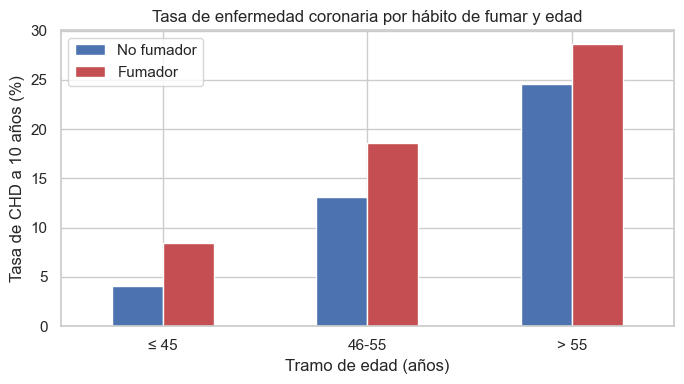

In [10]:
print("Edad media por hábito de fumar:")
print(df.groupby("currentSmoker")["age"].mean().round(1).rename({0: "No fumador", 1: "Fumador"}).to_string())

tramo_edad = pd.cut(df["age"], bins=[0, 45, 55, 100], labels=["≤ 45", "46-55", "> 55"])
estrat = (df.groupby([tramo_edad, "currentSmoker"], observed=True)["TenYearCHD"]
            .mean().mul(100).unstack().round(1))
estrat.columns = ["No fumador", "Fumador"]
display(estrat)

ax = estrat.plot(kind="bar", figsize=(7, 4), color=[COLORES["principal"], COLORES["riesgo"]], rot=0)
ax.set(xlabel="Tramo de edad (años)", ylabel="Tasa de CHD a 10 años (%)",
       title="Tasa de enfermedad coronaria por hábito de fumar y edad")
ax.legend(title="")
guardar_figura("p3_fig2_fumar_edad")

En los tres tramos de edad, los fumadores presentan una tasa observada de CHD mayor que los no fumadores. Esta comparación es descriptiva y depende de los límites elegidos para formar los tramos; tampoco elimina por completo el efecto de la edad.

Para estimar la relación entre tabaquismo y CHD controlando simultáneamente la edad y otros factores será necesario utilizar una regresión logística múltiple. Hasta realizar ese análisis, las diferencias observadas no deben interpretarse como un efecto causal.

## 4. Síntesis

| Prueba | Variables | Método | Resultado (α = 0,05) |
| --- | --- | --- | --- |
| 1 | `sysBP` vs. `TenYearCHD` | *t* de Welch y Mann-Whitney | Se rechaza H₀. La presión sistólica media es 13,3 mmHg mayor en quienes desarrollan CHD (d = 0,62). |
| 2 | `currentSmoker` vs. `TenYearCHD` | χ² de independencia | No se rechaza H₀ en la muestra completa. Por tramos de edad, los fumadores sí muestran tasas mayores. |